# 都道府県別データから考える高齢化対策
**氏名：原 子竜**

- **依頼元：** 日本の地域活性化を考える組織
- **読み手：** 地域の政策や住民サービスを考える担当者
- **調べたい問い：** 高齢化率が高い地域はどこか。また、人口密度との関係から、地域ごとにどのような支援を考えられるか。

このレポートでは、47都道府県のデータを使って高齢化率を比較します。さらに、可住地人口密度との関係も調べ、地域の状況に合わせた対策を考えます。

## 1. データを読み込む

`japan.csv`を読み込みます。最初にデータの行数・列数、先頭のデータ、必要な項目を確認します。

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# 日本語がグラフに表示されるようにフォントを設定する
plt.rcParams["font.family"] = ["Noto Sans", "Noto Sans CJK JP"]

# CSVファイルを読み込む
df = pd.read_csv("japan.csv")

# データの大きさと先頭5行を確認する
print("データの行数・列数：", df.shape)
display(df.head())

# 今回使う項目を確認する
print(df[["都道府県", "総人口", "65歳以上人口", "可住地面積"]].isnull().sum())

ModuleNotFoundError: No module named 'pandas'

## 2. 高齢化率を計算する

高齢化率は「65歳以上人口 ÷ 総人口 × 100」で求めます。全国全体の高齢化率は、都道府県ごとの割合を単純に平均するのではなく、全国の65歳以上人口を全国の総人口で割って計算します。あわせて、都道府県ごとの高齢化率の平均も確認します。

In [ ]:
df["高齢化率"] = df["65歳以上人口"] / df["総人口"] * 100

national_rate = df["65歳以上人口"].sum() / df["総人口"].sum() * 100
prefecture_mean = df["高齢化率"].mean()

print(f"全国全体の高齢化率：{national_rate:.1f}%")
print(f"都道府県ごとの高齢化率の平均：{prefecture_mean:.1f}%")
print(f"都道府県数：{len(df)}")

全国全体の高齢化率：29.0%
都道府県ごとの高齢化率の平均：31.4%
都道府県数：47


## 3. 高齢化率の高い地域・低い地域を比べる

高齢化率を基準に並べ替え、上位10都道府県と下位10都道府県を確認します。また、30％以上の都道府県がいくつあるかを`for`文で数えます。

In [ ]:
top10 = df.sort_values("高齢化率", ascending=False).head(10)
bottom10 = df.sort_values("高齢化率", ascending=True).head(10)

print("高齢化率 上位10都道府県")
display(top10[["都道府県", "高齢化率"]].round(1).reset_index(drop=True))

print("高齢化率 下位10都道府県")
display(bottom10[["都道府県", "高齢化率"]].round(1).reset_index(drop=True))

# for文で30%以上の都道府県を数える
count_over30 = 0
prefectures_over30 = []

for _, row in df.iterrows():
    if row["高齢化率"] >= 30:
        count_over30 += 1
        prefectures_over30.append(row["都道府県"])

print(f"高齢化率が30%以上の都道府県：{count_over30}県")
print("該当する地域：", "、".join(prefectures_over30))

高齢化率 上位10都道府県


,都道府県,高齢化率
0,秋田県,38.6
1,高知県,36.1
2,山口県,35.2
3,徳島県,34.9
4,島根県,34.8
5,青森県,34.8
6,山形県,34.8
7,岩手県,34.5
8,和歌山県,34.0
9,大分県,34.0


高齢化率 下位10都道府県


,都道府県,高齢化率
0,東京都,22.8
1,沖縄県,23.4
2,愛知県,25.6
3,神奈川県,25.8
4,滋賀県,26.8
5,埼玉県,27.4
6,大阪府,27.7
7,千葉県,28.0
8,福岡県,28.3
9,宮城県,28.9


高齢化率が30%以上の都道府県：33県
該当する地域： 北海道、青森県、岩手県、秋田県、山形県、福島県、茨城県、群馬県、新潟県、富山県、石川県、福井県、山梨県、長野県、岐阜県、静岡県、三重県、奈良県、和歌山県、鳥取県、島根県、岡山県、山口県、徳島県、香川県、愛媛県、高知県、佐賀県、長崎県、熊本県、大分県、宮崎県、鹿児島県


## 4. グラフで地域差を確認する

上位10都道府県と下位10都道府県をグラフにします。表だけでなくグラフにすることで、地域差を読み取りやすくします。

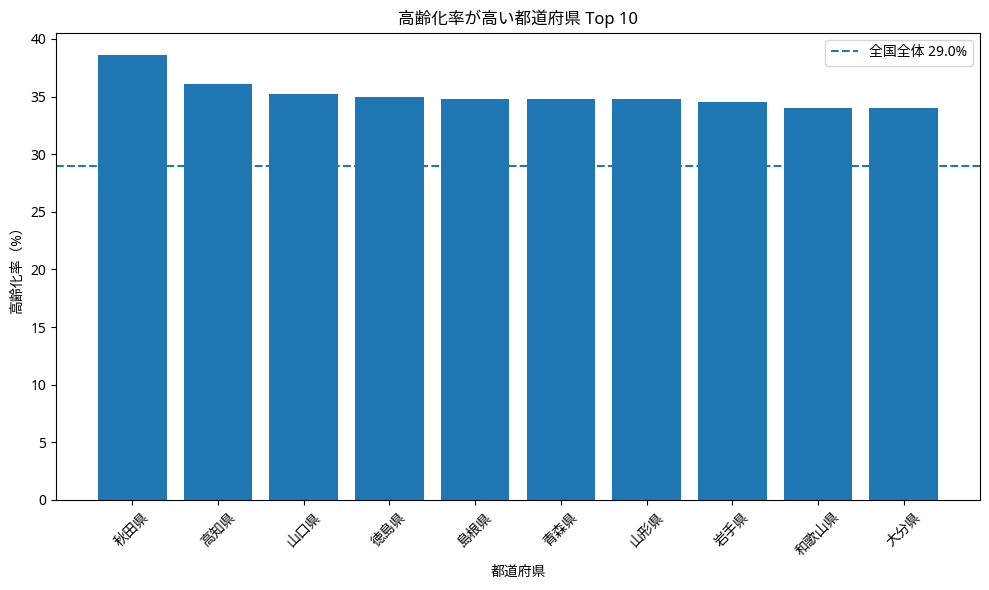

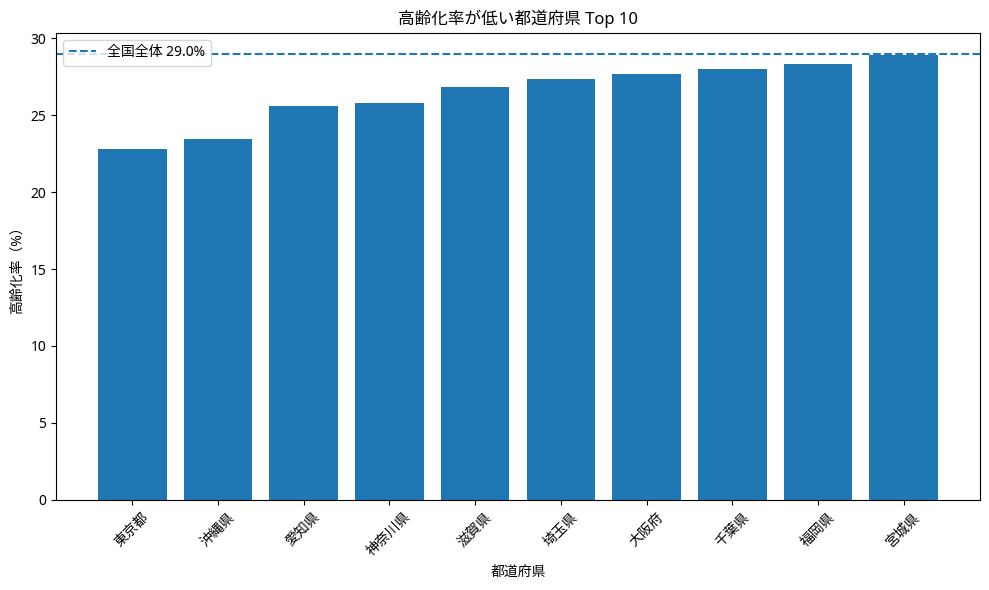

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(top10["都道府県"], top10["高齢化率"])
plt.axhline(national_rate, linestyle="--", label=f"全国全体 {national_rate:.1f}%")
plt.title("高齢化率が高い都道府県 Top 10")
plt.xlabel("都道府県")
plt.ylabel("高齢化率（%）")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.bar(bottom10["都道府県"], bottom10["高齢化率"])
plt.axhline(national_rate, linestyle="--", label=f"全国全体 {national_rate:.1f}%")
plt.title("高齢化率が低い都道府県 Top 10")
plt.xlabel("都道府県")
plt.ylabel("高齢化率（%）")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## 5. 高齢化率と可住地人口密度の関係を調べる

地域の人口の集まり方も関係するかを調べるため、「総人口 ÷ 可住地面積」で可住地人口密度を計算します。散布図と相関係数を使って、2つの項目にどのような関係があるかを確認します。

※相関があっても、一方がもう一方の原因だとは限りません。

高齢化率と可住地人口密度の相関係数：-0.66


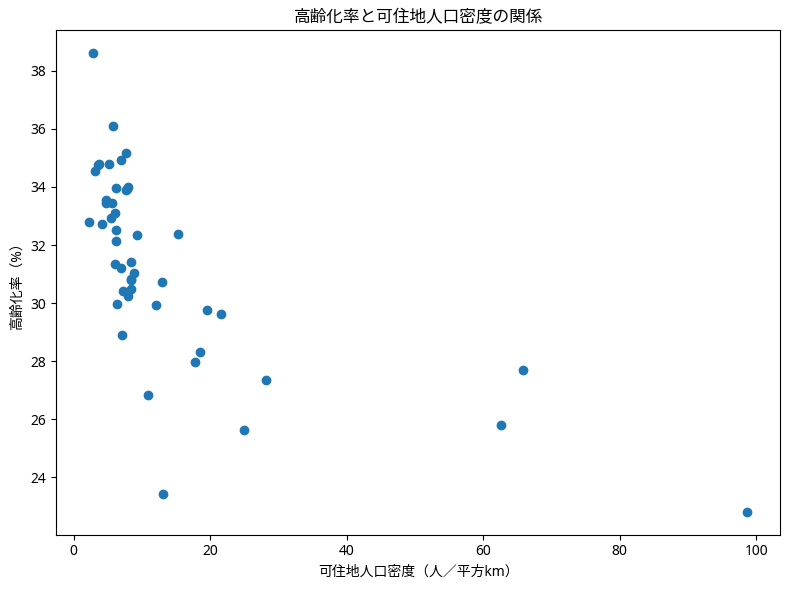

In [ ]:
df["可住地人口密度"] = df["総人口"] / df["可住地面積"]
correlation = df["高齢化率"].corr(df["可住地人口密度"])

print(f"高齢化率と可住地人口密度の相関係数：{correlation:.2f}")

plt.figure(figsize=(8, 6))
plt.scatter(df["可住地人口密度"], df["高齢化率"])
plt.xlabel("可住地人口密度（人／平方km）")
plt.ylabel("高齢化率（%）")
plt.title("高齢化率と可住地人口密度の関係")
plt.tight_layout()
plt.show()

## 6. 分析結果からわかったこと

今回のデータでは、秋田県の高齢化率が最も高く約38.6％、東京都が最も低く約22.8％でした。高齢化率が30％以上の都道府県は33県で、全国全体の高齢化率は約29.0％、都道府県ごとの平均は約31.4％でした。

また、高齢化率と可住地人口密度の相関係数は約-0.66でした。このデータでは、人口密度が高い都道府県ほど高齢化率が低い傾向が見られます。ただし、これは関係の強さを示すものであり、人口密度が高齢化率を下げる原因だと証明するものではありません。

## 7. 組織への提案

高齢化率が高い地域では、医療・介護サービスを利用しやすくすることや、買い物・通院などの移動を支える仕組みを充実させることが大切だと考えます。一方、人口が集中している地域でも、高齢者が多く住む地区を細かく確認し、必要な支援を届けることが必要です。

組織には、都道府県全体の数字だけで判断せず、市町村や地区ごとのデータも調べ、地域の実情に合った支援策を考えることを提案します。

今回の分析では、秋田県の高齢化率が約38.6％と最も高いことが分かりました。そこで、高齢化率が高い地域に向けて、次の3つの対策を提案します。

① 買い物や病院への移動を支援する

高齢者が車を運転しなくても生活できるように、スーパーや病院を回る予約制の送迎バスを運行します。例えば、週3回運行し、電話でも予約できる仕組みにします。

② 高齢者の見守りを強化する

一人暮らしの高齢者が安心して生活できるように、地域のボランティアや自治体が協力して、定期的に安否確認を行います。また、希望する人には緊急時に連絡できる機器を貸し出します。

③ 地域の交流場所を増やす

公民館などを活用し、週1回、高齢者が集まって体操や交流ができる場所を設けます。外出するきっかけをつくり、孤立を防ぐことを目指します。

これらの対策は、まず高齢化率の高い地域の一部で試験的に実施します。その後、利用者数や満足度などを調べ、効果があればほかの地域にも広げていきます。

## 8. 先週のレポートから改善した点・分析の注意点

先週は高齢化率の上位10都道府県と30％以上の都道府県数を中心に調べました。今回は、全国全体の高齢化率、上位・下位の比較、可住地人口密度との関係を追加し、結果から組織への提案までまとめました。

このデータは都道府県単位の比較です。都道府県内の市町村や地区による違い、年齢構成の変化、交通や医療機関の数までは分かりません。また、今回の分析だけでは高齢化の原因を特定できません。今後は市町村別のデータや複数年のデータも確認すると、より具体的な提案につながります。